# Functions

<b>Functions</b> are procedures or, if you will, subroutines that are called from the main program.


<b>Another definition</b> - functions are block statements that run when called, you can pass data (parameters) to it and it returns some data as the result.

<b>What does it mean practically?</b>
A function is a named set of instructions you can use again and again. You give it a name once, and whenever you need that job done, you just call the name.

<b>The machine analogy</b>

A function is like a small machine: you put something in, it does its job, and something comes out. A toaster takes bread and gives you toast. A function like len("hello") takes a word and gives you back 5.

<b>“Write once, use many times”: </b>
If you catch yourself copying the same lines of code over and over, put them in a function instead. Write them once, give them a name, and call that name whenever you need them. If you need to fix something, you fix it in one place.


<b>The advantages of using functions are</b>:

* Functions are reusable: A function, once written, can be used multiple times in a program (or even from different programs).
* Functions prevent redundancy: each functionality exists only once in the program. This makes the program easier to maintain and reduces error-proneness.
* Functions structure the code, making it easier to understand.

The idea is to put together some common or repeatedly done tasks and make functions, so that instead of repeating giant blocks of code for different inputs, we can use function calls to reuse the code contained in the function over and over again.


## Writing a function

A function definition in Python starts with the keyword `def` (many other languages use `function` instead). After the `def` follows the name of the function. This should ideally be a verb, since a function always does something. The name of the function is terminated by a pair of round brackets and a colon. This is followed by the actual function body which is indented, and defines what the function does.


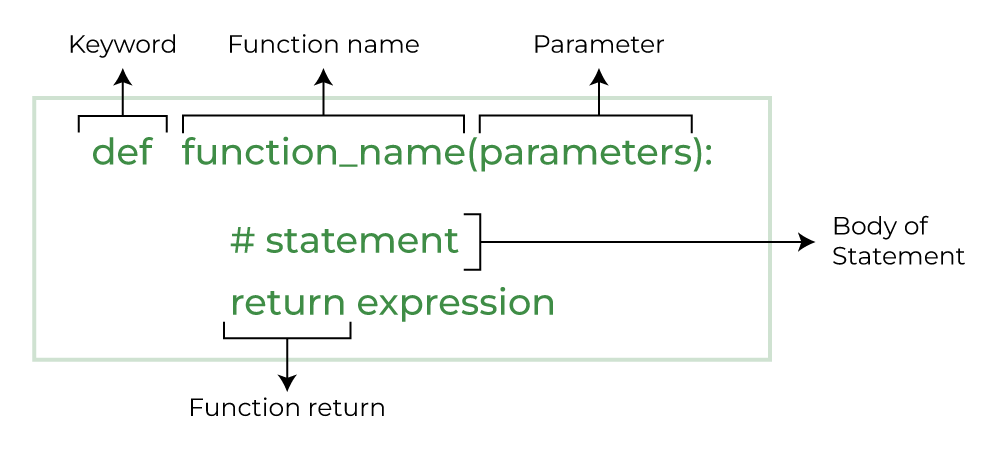

In [32]:
from IPython.display import Image
Image("img/function.png")

In [ ]:
def say_hello():
    print('Hello!')

With this we have written a function with the name `say_hello`. The function was created when we executed it, but it doesn't do anything yet because we haven't called it yet. The call to the function looks like this:

In [ ]:
say_hello()

You remember the function calls we used to make without actually knowing what we were doing?

* `print()`
* `type()`
* `len()`
* ...

In each case a function is called, which kindly someone else has already written for us, and which is available in every Python installation.

## Function parameters
The function `say_hello()` just written represents only the minimal version of a function: It always does the same thing. We can make the function more flexible by assigning **parameters** to it when we define it:

In [ ]:
def say_hello(username):
    print(f'Hello {username}!')


Here the function declaration specifies that a *parameter*, i.e. a value, must be passed to the function when it is called, which is then available within the function as the variable `username`. We can pass this value as *argument* when calling the function:

In [ ]:
say_hello('Otto')

In [ ]:
say_hello('Klara')

<div class="alert alert-block alert-info">
<b>Exercise 1 </b>
<p>Define a function <tt>print_email_address(first_name, family_name)</tt> that takes a <tt>first_name</tt> and <tt>family_name</tt> as parameters. In the function, create an email address in the format <tt>{first_name}.{family_name}@uni-graz.at</tt>.</p>
<p>So if you call <tt>print_email_address('Santa', 'Claus')</tt> you should get <tt>santa.claus@uni-graz.at</tt> as a result.
</div>

## Return values

### The default return value is `None`.

Each function returns a value when called. This is `None` unless otherwise specified. Here is an example of this return value that is not explicitly specified:

In [ ]:
retval = say_hello('Otto')  # Store return value to variable
print(f'Return: {retval}')

### Explicit return values

Explicit return values are always useful when, for example, a function calculates something and the result of the calculation is to be used in the main program.

The following function is very similar to the `print_email_address` which we defined in the previous exercise. However, the function we wrote above, only prints out the results on our screen, but it does not return anything. In contrast, now we are defining a function `generate_email_address`, which returns the email address as a **return value**. 

As such, it does not print anything on our screens (although we can print the result out with the `print` function of course), but returns the email address as a return value which can be further used by the program.

In [ ]:
def generate_email_address(first_name, family_name):
    email = f'{first_name}.{family_name}@uni-graz.at'.lower()
    return email

In [ ]:
new_email = generate_email_address('Santa', 'Claus')

In [ ]:
print(new_email)

<div class="alert alert-block alert-info">
<b>Exercise 2 </b>
<p>Write a <tt>count_distinct_chars()</tt> function that takes a <tt>text</tt> parameter. In the function, determine how many different characters <tt>text</tt> consists of (if you don't remember how, look in the notebook on sets) and return this number as the result.</p>
<p>So if you call <tt>result = count_distinc_chars('abcabc')</tt> and then print the result, you should get <tt>3</tt> as a result.
</div>

In [ ]:
result = count_distinct_chars('abcabc')
print(result)

### A real example
Imagine you want to compare the most popular first names of 1984 and 2015 (using the files in the `data/names folder)`. Until now, for each of the two years, we would read in the names from the corresponding file as a list:

In [ ]:
with open('data/names/first_1984.txt') as fh:
    names_84 = [n.rstrip() for n in fh.readlines()]

However, instead of rewriting this code for each file to be examined, we can program a corresponding function `read_names()` and call it several times:

In [ ]:
def read_names(filename):
    with open(filename) as fh:
        names = [n.rstrip() for n in fh.readlines()]
    return names

In [ ]:
names_84 = read_names('data/names/names_2001-2005.txt')
names_15 = read_names('data/names/first_2015.txt')
print(names_84[:10]) # print the first 10 names from 1984

If we can assume that we always find the most popular first names of each year in the directory `data/names/`, and the file names are always structured the same way (`first_YYY.txt`), we can also write a more specialized function:

In [ ]:
def read_names_for_year(year):
    filename = f"data/names/first_{year}.txt"
    with open(filename) as fh:
        names = [n.rstrip() for n in fh.readlines()]
    return names

In [ ]:
names_84 = read_names_for_year(1984)
names_15 = read_names_for_year(2015)
print(names_84[:10])

### Functions avoid redundancy
The second solution is not as general-purpose as the first one (because it assumes that all first-name files are located in a certain directory and follow a certain naming scheme), but it offers another advantage besides the more compact notation when called: If, for example, something changes in the directory structure, we don't need to track this change in every single call of the function, but in exactly one place: in the function.

Let's assume that for some reason we need to change the directory name from `data/names` to `data/popular_firstnames`. While in the first example we would have to search for all calls of `read_names()` and change the directory name there (which would not be so time-consuming with two calls now), in the second case we need to make the change only once (in the function):

In [ ]:
def read_names_for_year(year):
    filename = f"data/popular_firstnames/first_{year}.txt"
    with open(filename) as fh:
        names = [n.rstrip() for n in fh.readlines()]
    return names

But here is a warning: The reusability of a function depends strongly on its flexibility (i.e.: parameterizability). The more specialized a function is, the less often it can be reused. The opposite is also true: You can write a function very flexibly by using many parameters, but at some point the use of the function becomes so complicated that you don't want to use it anymore.

## A function with multiple parameters

In principle, a function can have any number of parameters. In practice, unless you have good reasons, you should limit yourself to a maximum of 3 or 4 parameters. 

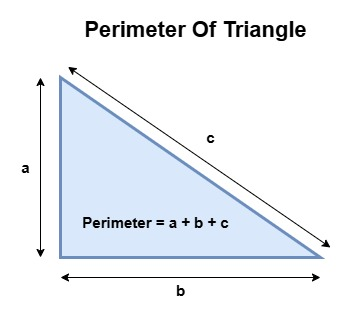
Source: https://pynative.com/python-perimeter-of-triangle/

In [ ]:
def calculate_triangle_perimeter(a, b, c):
    perimeter = a + b + c
    return perimeter

In [ ]:
perimeter = calculate_triangle_perimeter(80, 40, 40)
print(perimeter)

## Comments
Documentation of source code is important because it explains the code and makes it easier to understand for later editors (which will often be you). For this purpose comments are used. The comment sign in Python is `#`. Everything to the right of the comment sign is ignored when the program is executed.

However, you should only comment things that cannot be easily deduced from the code anyway:

~~~
...
    i += 1 # increase i by 1
...    
~~~

is a good example of an unnecessary comment. As a rule of thumb, you should take to heart: Don't document *what* happens, but *why* it happens.

Remember our encrypting exercise? Here, the comments might been beneficial to document what is happening and why:

~~~
text_to_encrypt = 'Hello'
alphabet = 'abcdefghijklmnopqrstuvwxyz'   # we need an alphabet as a reference
encrypted_text = ''   # into this empty string, we will save the result, letter by letter

for letter in text_to_encrypt:
    letter_lower = letter.lower()
    letter_index = alphabet.find(letter_lower)   # find the current letter index in the alphabet
    new_index = letter_index + 2  # increase index by 2 to move 2 letter further in the alphabet
    encrypted_text += alphabet[new_index]   # add the encrypted letter to the resulting string
~~~

## Docstrings
Python offers a special feature with docstrings. In the form of such docstrings, the documentation becomes part of the function (docstrings can also be used for modules and packages, but we'll get to that later). A docstring must be placed immediately after the function declaration in the form of a string: 

In [ ]:
def calculate_triangle_perimeter(a, b, c):
    "Return the perimeter of a triangle."
    perimeter = a + b + c
    return perimeter

The docstring in this example really becomes part of the function and can be queried:

In [ ]:
calculate_triangle_perimeter.__doc__

For example, Python's built-in `help()` function takes advantage of this to display the description of a function. But integrated development environments (IDEs) also use docstrings to display context-sensitive information about the use of a function.

In [ ]:
help(calculate_triangle_perimeter)

This is also available in a Jupyter notebook. In the cell below, write a function name (e.g. `calculate_triangle_perimeter`) and then press the `Shift` and `Tab` keys (i.e. the shift and tab keys) simultaneously.

In [ ]:
calculate_triangle_perimeter

### Multiline docstrings
In addition to the basic form, more detailed docstrings can also be written:

In [ ]:
def calculate_triangle_perimeter(a, b, c):
    """Return the perimeter of a triangle.
    
    Args:
        a -- length of the first side 'a' in cm
        b -- length of the second side 'b' in cm
        c -- length of the third side 'c' in cm
        
    Returns:
        Perimeter in cm as an integer or a float."""
    
    perimeter = a + b + c
    return perimeter

In [ ]:
help(calculate_triangle_perimeter)

<div class="alert alert-block alert-info">
<b>Exercise Func-3</b>
<p>Create a function <tt>is_even(number)</tt>, which returns for a given number True/False indicating if it's even or not. 

Test with the following examples:

<tt>
    <li>print(is_even(2)) # should return True</li>
    <li>print(is_even(3)) # should return False</li>
    <li>print(is_even(-4)) # should return True</li>
</tt>
</p>
<div>

<div class="alert alert-block alert-info">
<b>Exercise Func-4</b>
<p> Define a function <tt>find_max(list_of_numbers)</tt> which returns the largest number from a list of numbers. Do NOT use the <tt>max</tt> or <tt>sort</tt> function, instead, use a <tt>for</tt> loop together with conditions.

<li>result = find_max([1, 9, 3, 4, 6, 5, 9, 8, 5, 6 ])</li>
<li>print(result)</li>
<li>output: 9</li>    
</p>
<div>

## Functions with multiple return values
In most programming languages, functions can only return one value (unless, of course, the return values ​​are "packed" in a container). In Python, however, two or more values ​​can be returned directly (python interprets two or more values ​​separated by commas as a tuple -- the actual return value is therefore a tuple).

In the following example, we want to return two values - min and max - from a list of numbers.

In [ ]:
def get_min_max(list_of_numbers):
    min_num = min(list_of_numbers)
    max_num = max(list_of_numbers)
    return min_num, max_num

min_num, max_num = get_min_max([1, 9, 3, 4, 6, 5, 9, 8, 5, 6])
print(f'The smallest number is {min_num}, the largest number is {max_num}.')

## Default parameters
Normally, the order of the arguments when calling the function must correspond to the order of the parameters in the function declaration, and all arguments must also be passed:

~~~
def set_userdata(username, age):
     ...
    
set_userdata('otto', 20)
~~~

If we do not expect a parameter to be mandatory, we can set a default value for it:

In [ ]:
def set_userdata(username, age=None):
    return username, age

print(set_userdata('Martin', 20))
print(set_userdata('Anna'))

If the value is supplied, it will be used in the function, if not, the default value will be used. Such parameters must be **after** all other parameters, which is why the following code block does not work.

In [ ]:
def set_userdata(age=None, username):
    return username, age

If more than one default parameter is defined, keyword arguments can be used when calling the function, which means that we no longer have to adhere to the given order:

In [ ]:
def set_userdata(username, age=None, weight=None, height=None):
    return username, age, weight, height

print(set_userdata('Klara', height=181))

In [ ]:
print(set_userdata('Klara', height=181, age=25))

## Functions with any number of parameters.
Sometimes, at the time the function is written, it is not yet known how many parameters to expect. In this case, we can write the function declaration like this:

~~~
def my_function(*args):
~~~

In this case, all values are packed into a tuple:


In [ ]:
def my_function(*args):
    print(type(args))
    
my_function(1, 2, 3)    

With this we can write, for example, a function to determine the arithmetic mean: 

In [ ]:
def avg(*args):
    return sum(args) / len(args)

avg(1, 2, 3, 4)

# Print vs return

`print` shows the human user an output representing what is going on inside the computer. The computer cannot make use of that printing. 

On the other hand,`return` is how a function gives back a value. This value is often unseen by the human user, but it can be used by the computer in further functions.

`print` will not in any way affect a function. It is simply there for the human user’s benefit. It is very useful for understanding how a program works and can be used in debugging to check various values in a program without interrupting the program.

`return` is the main way that a function returns a value. All functions will return a value, and if there is no return statement, it will return `None`. The value that is returned by a function can then be further used as an argument passed to another function, stored as a variable, or just printed for the benefit of the human user.



In [ ]:
def function_that_prints():
    print ("I printed")

def function_that_returns():
    return ("I returned")

In [ ]:
f1 = function_that_prints()
f2 = function_that_returns()

In [ ]:
print("Now let us see what the values of f1 and f2 are")

In [ ]:
print(f1)

In [ ]:
print(f2)

<div class="alert alert-block alert-info">
<b>Exercise Func-5</b>
<p> Define a function <tt>find_longer_string(string1, string2)</tt> which returns the longer string from two strings.
<li>result = find_longer_string('dog', 'squirrel')</li>
<li>print(result)</li>
<li>output: 'squirrel</li>    
</p>
<div>

# Literature
*  Python Tutorial: 
	* Kapitel 4.6 - Defining Functions 
      (https://docs.python.org/3/tutorial/controlflow.html#defining-functions)
    * Kapitel 4.7 - More on Defining Functions
	  (https://docs.python.org/3/tutorial/controlflow.html#more-on-defining-functions)
* Sweigart: https://automatetheboringstuff.com/2e/chapter3/  
* Geeks4geeks: https://www.geeksforgeeks.org/python-functions/
* W3Schools: https://www.w3schools.com/python/python_functions.asp
* max() - https://www.w3schools.com/python/ref_func_max.asp
* Video: Ned Batchelder - Facts and Myths about Python names and values - PyCon 
    2015 (https://www.youtube.com/watch?v=_AEJHKGk9ns)
               

This notebook is a part of the course Introduction to Programming at the University of Graz. The notebook was adapted by Klara Venglarova from the original notebook of Lucija Brozić.